  Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-macosx_11_0_arm64.whl.metadata (5.2 kB)
Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp314-cp314-macosx_11_0_arm64.whl (283 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 417.4 kB/s  0:00:07 eta 0:00:01
Using cached kiwisolver-1.5.1-cp314-cp314-macosx_11_0_arm64.whl (64 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [matplotlib]5 [matplotlib]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Shape: (200000, 11)

First 5 rows:
   Severity           Start_Time  Star

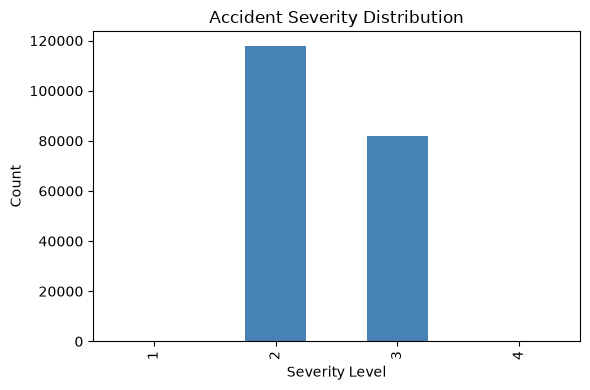


Top 15 weather conditions:
Weather_Condition
Clear                           94476
Overcast                        26454
Mostly Cloudy                   23197
Partly Cloudy                   17883
Scattered Clouds                16833
Light Rain                       7046
Haze                             3213
Light Snow                       1504
Fair                             1489
Rain                             1488
Fog                               665
Heavy Rain                        464
Thunderstorm                      346
Light Thunderstorms and Rain      343
Light Drizzle                     335
Name: count, dtype: int64

Sunrise/Sunset split:
Sunrise_Sunset
Day      136654
Night     63332
Name: count, dtype: int64

Correlation with Severity:
Severity           1.000000
Temperature(F)     0.018530
Visibility(mi)    -0.005052
Wind_Speed(mph)   -0.010692
Humidity(%)       -0.021089
Name: Severity, dtype: float64


In [5]:
import pandas as pd
%pip install matplotlib
import matplotlib.pyplot as plt


df = pd.read_csv(
    '../US_Accidents_March23.csv',
    usecols=['Severity', 'Start_Time', 'Start_Lat', 'Start_Lng',
              'Temperature(F)', 'Humidity(%)', 'Visibility(mi)',
              'Wind_Speed(mph)', 'Precipitation(in)',
              'Weather_Condition', 'Sunrise_Sunset'],
    nrows=200000
)

print("Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())


print("\nColumn info:")
df.info()


print("\nMissing values (count):")
print(df.isnull().sum().sort_values(ascending=False))

print("\nMissing values (%):")
print((df.isnull().sum() / len(df) * 100).sort_values(ascending=False).round(2))


print("\nSummary statistics:")
print(df.describe())


print("\nSeverity distribution:")
print(df['Severity'].value_counts().sort_index())

plt.figure(figsize=(6, 4))
df['Severity'].value_counts().sort_index().plot(kind='bar', color='steelblue')
plt.title('Accident Severity Distribution')
plt.xlabel('Severity Level')
plt.ylabel('Count')
plt.tight_layout()
plt.show()



print("\nTop 15 weather conditions:")
print(df['Weather_Condition'].value_counts().head(15))


print("\nSunrise/Sunset split:")
print(df['Sunrise_Sunset'].value_counts())


numeric_cols = ['Severity', 'Temperature(F)', 'Humidity(%)', 'Visibility(mi)', 'Wind_Speed(mph)']
print("\nCorrelation with Severity:")
print(df[numeric_cols].corr()['Severity'].sort_values(ascending=False))